# Medical ML baselines and leakage

Are we predicting for a new person, or recognizing someone the model has already seen?

Fall 2024.


Predict which model can benefit from another observation of a test group. The target is an unseen group; the contaminated branch deliberately violates that target.

{'proper': {'training_rows': 240, 'test_rows': 40, 'training_groups': 80, 'test_groups': 40, 'overlap_groups': 0}, 'leaky': {'training_rows': 240, 'test_rows': 40, 'training_groups': 80, 'test_groups': 40, 'overlap_groups': 40}}


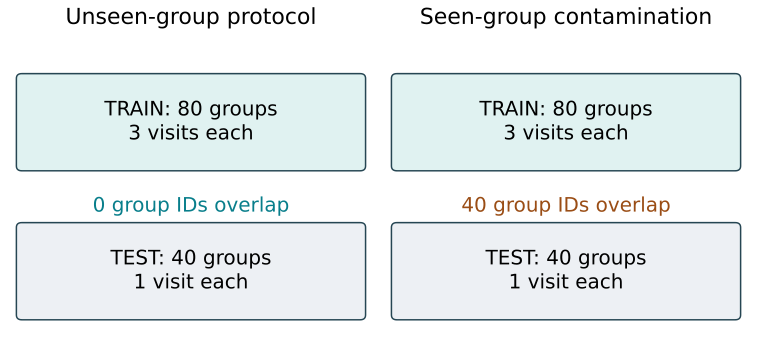

In [1]:
from demo import run
from IPython.display import SVG, display
report = run()
print({k:report[k]['audit'] for k in ('proper','leaky')})
display(SVG(filename='group-protocol.svg'))

Interpret the same-case comparison. Inspect both class recalls before accepting a headline accuracy.

{'constant': {'confusion_true_rows_predicted_columns': [[20, 0], [20, 0]], 'accuracy': 0.5, 'recall_class0': 1.0, 'recall_class1': 0.0, 'balanced_accuracy': 0.5}, 'signal_logistic': {'confusion_true_rows_predicted_columns': [[13, 7], [4, 16]], 'accuracy': 0.725, 'recall_class0': 0.65, 'recall_class1': 0.8, 'balanced_accuracy': 0.7250000000000001}, 'all_feature_1nn': {'confusion_true_rows_predicted_columns': [[14, 6], [8, 12]], 'accuracy': 0.65, 'recall_class0': 0.7, 'recall_class1': 0.6, 'balanced_accuracy': 0.6499999999999999}}
{'constant': {'confusion_true_rows_predicted_columns': [[20, 0], [20, 0]], 'accuracy': 0.5, 'recall_class0': 1.0, 'recall_class1': 0.0, 'balanced_accuracy': 0.5}, 'signal_logistic': {'confusion_true_rows_predicted_columns': [[14, 6], [4, 16]], 'accuracy': 0.75, 'recall_class0': 0.7, 'recall_class1': 0.8, 'balanced_accuracy': 0.75}, 'all_feature_1nn': {'confusion_true_rows_predicted_columns': [[20, 0], [0, 20]], 'accuracy': 1.0, 'recall_class0': 1.0, 'recall_cla

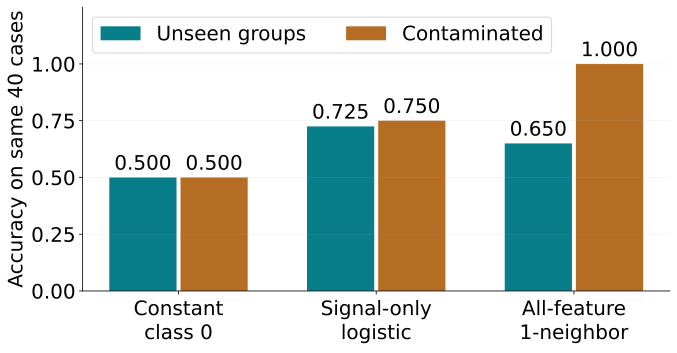

In [2]:
print(report['proper']['models'])
print(report['leaky']['models'])
display(SVG(filename='baseline-comparison.svg'))

Modify only test rows and verify that the fitted training transform is unchanged. Then try the group guard on the contaminated branch; the error is the expected result.

In [3]:
import numpy as np
from demo import make_data, fit_scale, audit_split
x,y,groups,splits = make_data()
before = fit_scale(x[splits['proper']])
x[splits['test'],0] += 100
after = fit_scale(x[splits['proper']])
print('Training means unchanged:', np.allclose(before[0], after[0]))
try:
    audit_split(groups, splits['leaky'], splits['test'])
except ValueError as exc:
    print('Expected audit failure:', exc)

Training means unchanged: True
Expected audit failure: Group overlap violates the unseen-group target.
